# Equilibrium MC, GCMC and rate-based KMC

Original educational notebook. Read the linked course chapters. All synthetic models are labeled; no material property is inferred from a short run.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p/'scripts/numerics.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Extract the complete repository, then open this notebook from its root or notebooks folder.')
sys.path.insert(0, str(ROOT))
np.set_printoptions(precision=5)


## Ideal-gas GCMC
Equal insertion/deletion move selection, including rejected deletion at N=0. Mean and variance should approach zV. MC steps are not seconds.

Mean / variance / analytical: 4.988073684210526 5.026963026149584 5
{'mean': 4.988073684210526, 'se': 0.03261365772378742, 'ci_low': 4.923318502274933, 'ci_high': 5.05282886614612, 'blocks': 95, 'block_size': 1000, 'discarded_tail': 0, 'confidence': 0.95}


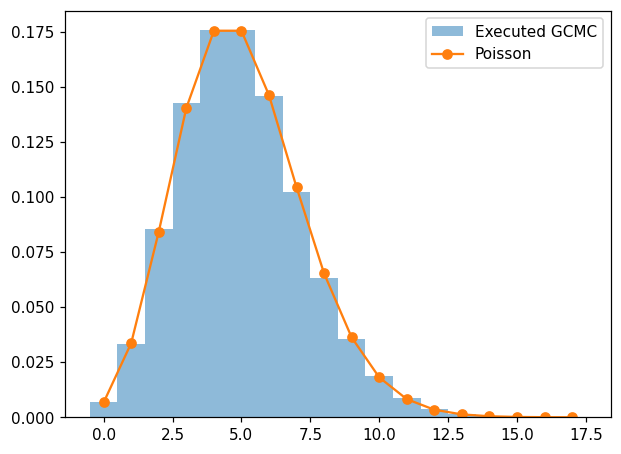

In [2]:
from scripts.numerics import ideal_gcmc,two_state_kmc,block_summary
from scipy.stats import poisson
n=ideal_gcmc(activity=.5,volume=10,steps=100000,burn=5000,seed=3)
print('Mean / variance / analytical:',n.mean(),n.var(),5)
k=np.arange(18)
plt.hist(n,bins=np.arange(-.5,18.5),density=True,alpha=.5,label='Executed GCMC')
plt.plot(k,poisson.pmf(k,5),'o-',label='Poisson');plt.legend();plt.show()
print(block_summary(n,1000))

## KMC time weighting
State 0→1 has rate 2 s⁻¹; 1→0 has rate 1 s⁻¹. This is a synthetic rate model with specified physical units.

Time-weighted state-1 fraction: 0.6658797621354602
Event-weighted fraction (wrong for occupancy): 0.5
Analytical occupancy: 0.6666666666666666


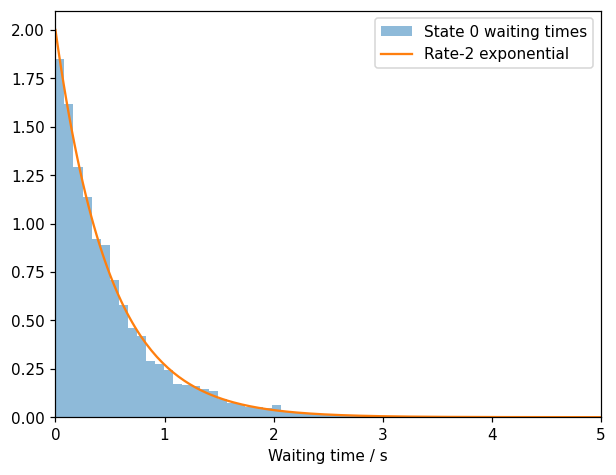

In [3]:
state,wait=two_state_kmc(a=2,b=1,tmax=10000,seed=4)
print('Time-weighted state-1 fraction:',np.sum(state*wait)/wait.sum())
print('Event-weighted fraction (wrong for occupancy):',state.mean())
print('Analytical occupancy:',2/3)
plt.hist(wait[state==0],bins=60,density=True,alpha=.5,label='State 0 waiting times')
t=np.linspace(0,5,200);plt.plot(t,2*np.exp(-2*t),label='Rate-2 exponential')
plt.xlim(0,5);plt.xlabel('Waiting time / s');plt.legend();plt.show()

**Exercise:** multiply both rates by ten and keep the observation window fixed. What changes in equilibrium population, event count and precision? Explain why no analogous physical clock follows from an ordinary GCMC swap probability.